## **Read the full Report:**
https://github.com/Musfique-Ahmed/Marketing-Analysis-DS-4115-/blob/main/Assignments/Assignment_3/Lab3_RFM_Analytics_Report.md

In [24]:

# Import necessary libraries

import pandas as pd
import numpy as np
import datetime as dt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

import matplotlib.pyplot as plt
import seaborn as sns

# Set visualization theme
sns.set_theme(style="whitegrid")

print("Environment successfully configured!")


Environment successfully configured!


## Synthetic Customer Transaction Dataset

In [25]:

# Set random seed for reproducibility
np.random.seed(42)

n_transactions = 15000
start_date = dt.datetime(2025, 1, 1)

# Generate synthetic transaction attributes
customer_ids = [
    f"CUST_{np.random.randint(1000, 2000)}"
    for _ in range(n_transactions)
]

transaction_ids = [
    f"TXN_{str(i).zfill(6)}"
    for i in range(1, n_transactions + 1)
]

random_days = np.random.randint(0, 365, size=n_transactions)

transaction_dates = [
    start_date + dt.timedelta(days=int(d))
    for d in random_days
]

order_values = np.round(
    np.random.exponential(scale=75, size=n_transactions) + 10,
    2
)

# Create DataFrame
raw_df = pd.DataFrame({
    'TransactionID': transaction_ids,
    'CustomerID': customer_ids,
    'TransactionDate': transaction_dates,
    'OrderValue': order_values
})

# Save raw transaction logs
raw_df.to_csv('raw_customer_transactions.csv', index=False)

print(f"Dataset successfully created with {len(raw_df)} transaction logs across {raw_df['CustomerID'].nunique()} unique customers!")

raw_df.head()


Dataset successfully created with 15000 transaction logs across 1000 unique customers!


,TransactionID,CustomerID,TransactionDate,OrderValue
0,TXN_000001,CUST_1102,2025-05-11,53.44
1,TXN_000002,CUST_1435,2025-03-08,318.28
2,TXN_000003,CUST_1860,2025-08-16,73.14
3,TXN_000004,CUST_1270,2025-06-12,27.00
4,TXN_000005,CUST_1106,2025-01-15,35.98


# Part 1: RFM Feature Engineering

In [26]:

# Define snapshot date
# (1 day after the latest transaction date in the dataset)

snapshot_date = raw_df['TransactionDate'].max() + dt.timedelta(days=1)

print("Snapshot Date:", snapshot_date)


Snapshot Date: 2026-01-01 00:00:00


### Calculate RFM Metrics

In [27]:

# Group by CustomerID and compute RFM metrics

rfm_df = raw_df.groupby('CustomerID').agg({

    'TransactionDate': lambda x: (snapshot_date - x.max()).days,

    'TransactionID': 'count',

    'OrderValue': 'sum'

}).reset_index()

# Rename columns to standard RFM nomenclature

rfm_df.columns = [
    'CustomerID',
    'Recency',
    'Frequency',
    'Monetary'
]

print(f"RFM aggregated for {len(rfm_df)} customers.")

rfm_df.head()


RFM aggregated for 1000 customers.


,CustomerID,Recency,Frequency,Monetary
0,CUST_1000,15,19,1586.42
1,CUST_1001,39,15,1061.24
2,CUST_1002,10,12,1240.64
3,CUST_1003,40,10,1003.76
4,CUST_1004,30,10,1058.63


In [28]:

# Display first five customer records
rfm_df.head()


,CustomerID,Recency,Frequency,Monetary
0,CUST_1000,15,19,1586.42
1,CUST_1001,39,15,1061.24
2,CUST_1002,10,12,1240.64
3,CUST_1003,40,10,1003.76
4,CUST_1004,30,10,1058.63


In [29]:

# Check dataset information
print("Dataset Shape:", rfm_df.shape)

# Check missing values
print("\nMissing Values:")
print(rfm_df.isnull().sum())

# Statistical summary
print("\nRFM Statistical Summary:")
display(rfm_df[['Recency', 'Frequency', 'Monetary']].describe())


Dataset Shape: (1000, 4)

Missing Values:
CustomerID    0
Recency       0
Frequency     0
Monetary      0
dtype: int64

RFM Statistical Summary:


,Recency,Frequency,Monetary
count,1000.000000,1000.000000,1000.00000
mean,24.622000,15.000000,1281.24096
std,23.788169,3.985459,435.97341
min,1.000000,5.000000,175.95000
25%,7.750000,12.000000,988.19250
50%,17.000000,15.000000,1250.21500
75%,34.000000,18.000000,1533.10000
max,144.000000,29.000000,2760.52000


# Part 2: Feature Scaling & K-Means Clustering

### Standardize RFM Features

In [30]:

# Select numeric features for clustering
rfm_features = rfm_df[['Recency', 'Frequency', 'Monetary']]

# Display selected features
rfm_features.head()


,Recency,Frequency,Monetary
0,15,19,1586.42
1,39,15,1061.24
2,10,12,1240.64
3,40,10,1003.76
4,30,10,1058.63


In [31]:

# Initialize StandardScaler
scaler = StandardScaler()

# Fit and transform RFM features
rfm_scaled = scaler.fit_transform(rfm_features)

# Convert scaled array back to DataFrame
rfm_scaled_df = pd.DataFrame(
    rfm_scaled,
    columns=[
        'Recency_Scaled',
        'Frequency_Scaled',
        'Monetary_Scaled'
    ]
)

# Display scaled features
rfm_scaled_df.head()


,Recency_Scaled,Frequency_Scaled,Monetary_Scaled
0,-0.404689,1.004151,0.700345
1,0.604721,0.000000,-0.504873
2,-0.614983,-0.753113,-0.093174
3,0.646779,-1.255188,-0.636782
4,0.226192,-1.255188,-0.510862


In [32]:

# Check mean and standard deviation after scaling

print("Mean of Scaled Features:")
print(rfm_scaled_df.mean().round(4))

print("\nStandard Deviation of Scaled Features:")
print(rfm_scaled_df.std().round(4))


Mean of Scaled Features:
Recency_Scaled      0.0
Frequency_Scaled    0.0
Monetary_Scaled     0.0
dtype: float64

Standard Deviation of Scaled Features:
Recency_Scaled      1.0005
Frequency_Scaled    1.0005
Monetary_Scaled     1.0005
dtype: float64


### Train K-Means Clustering Model

In [33]:

# Train K-Means model

kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

# Predict cluster labels
rfm_df['Cluster'] = kmeans.fit_predict(rfm_scaled)

# Display first five records
rfm_df.head()


,CustomerID,Recency,Frequency,Monetary,Cluster
0,CUST_1000,15,19,1586.42,3
1,CUST_1001,39,15,1061.24,0
2,CUST_1002,10,12,1240.64,1
3,CUST_1003,40,10,1003.76,1
4,CUST_1004,30,10,1058.63,1


### Analyze Cluster Performance

In [34]:

# Inspect mean values for each cluster

cluster_summary = rfm_df.groupby('Cluster').agg({
    'Recency': 'mean',
    'Frequency': 'mean',
    'Monetary': ['mean', 'count']
}).round(2)

print("Cluster Summary (Mean Values):")
print(cluster_summary)


Cluster Summary (Mean Values):
        Recency Frequency Monetary      
           mean      mean     mean count
Cluster                                 
0         17.77     16.01  1356.02   430
1         20.62     11.42   885.01   295
2         78.38     11.85  1015.82   104
3         16.06     20.56  1938.18   171


### Visualize the Clusters

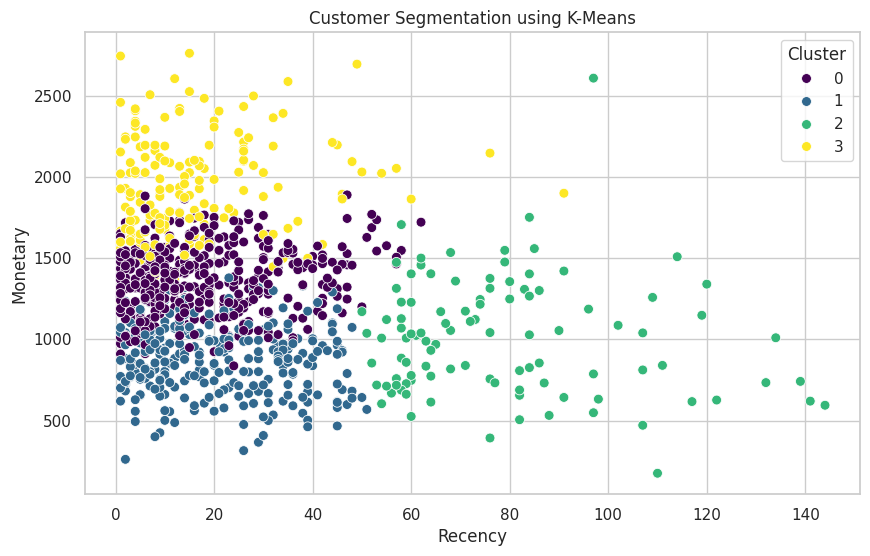

In [35]:

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=rfm_df,
    x='Recency',
    y='Monetary',
    hue='Cluster',
    palette='viridis',
    s=50
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Recency')
plt.ylabel('Monetary')
plt.legend(title='Cluster')
plt.show()


### Assign Customer Personas

In [36]:

# Map clusters to customer personas
persona_mapping = {
    0: 'Loyal Customers',
    1: 'Recent / New Visitors',
    2: 'At-Risk / Lost',
    3: 'Champions'
}

# Assign customer personas
rfm_df['Customer_Persona'] = rfm_df['Cluster'].map(persona_mapping)

# Display updated dataset
rfm_df.head()


,CustomerID,Recency,Frequency,Monetary,Cluster,Customer_Persona
0,CUST_1000,15,19,1586.42,3,Champions
1,CUST_1001,39,15,1061.24,0,Loyal Customers
2,CUST_1002,10,12,1240.64,1,Recent / New Visitors
3,CUST_1003,40,10,1003.76,1,Recent / New Visitors
4,CUST_1004,30,10,1058.63,1,Recent / New Visitors


### Verify Customer Personas

In [37]:

# Count customers in each persona

persona_counts = rfm_df['Customer_Persona'].value_counts()

print("Customer Persona Distribution:")
print(persona_counts)


Customer Persona Distribution:
Customer_Persona
Loyal Customers          430
Recent / New Visitors    295
Champions                171
At-Risk / Lost           104
Name: count, dtype: int64


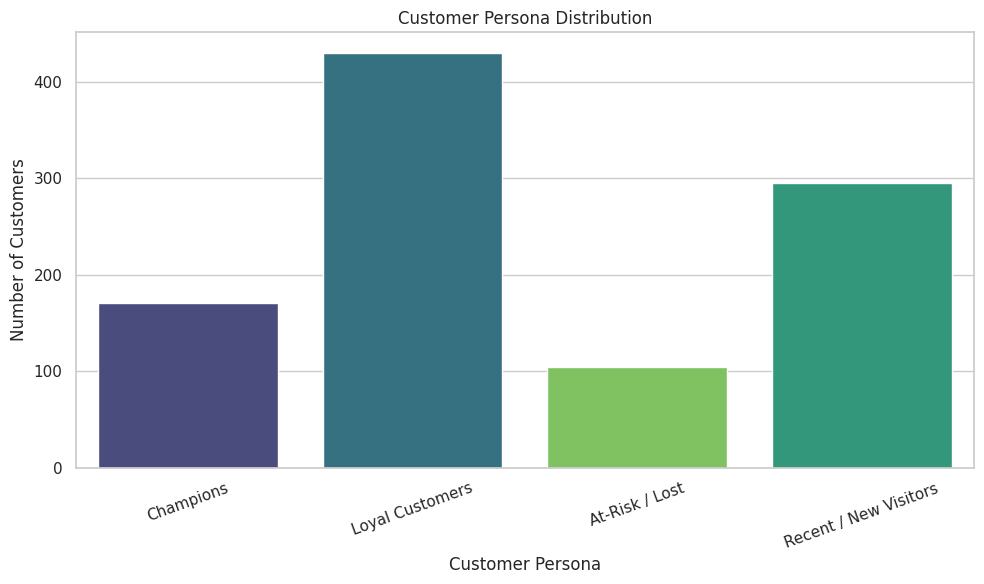

In [38]:

plt.figure(figsize=(10, 6))

sns.countplot(
    data=rfm_df,
    x='Customer_Persona',
    hue='Customer_Persona',
    order=[
        'Champions',
        'Loyal Customers',
        'At-Risk / Lost',
        'Recent / New Visitors'
    ],
    palette='viridis',
    legend=False
)

plt.title('Customer Persona Distribution')
plt.xlabel('Customer Persona')
plt.ylabel('Number of Customers')
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


### Export Segmented Customer Dataset

In [39]:

# Export the labeled dataset for Tableau

rfm_df.to_csv(
    'rfm_segmented_customers.csv',
    index=False
)

print(
    "Segmented dataset exported successfully "
    "as 'rfm_segmented_customers.csv'!"
)

# Verify final dataset
rfm_df.head()


Segmented dataset exported successfully as 'rfm_segmented_customers.csv'!


,CustomerID,Recency,Frequency,Monetary,Cluster,Customer_Persona
0,CUST_1000,15,19,1586.42,3,Champions
1,CUST_1001,39,15,1061.24,0,Loyal Customers
2,CUST_1002,10,12,1240.64,1,Recent / New Visitors
3,CUST_1003,40,10,1003.76,1,Recent / New Visitors
4,CUST_1004,30,10,1058.63,1,Recent / New Visitors


In [40]:

from google.colab import files

files.download('rfm_segmented_customers.csv')


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Tablue Dashboard: https://public.tableau.com/authoring/Lab3_RFM_Tableau_Dashboard_17953711299060/CustomerPersonaRFMDashboard#1